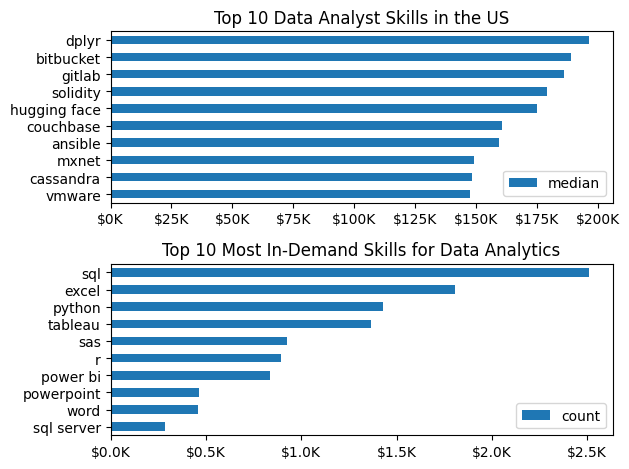

In [32]:
import ast
import pandas as pd
from datasets import load_dataset
import matplotlib.pyplot as plt

# Loading Data
dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

# Data Cleanup
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)
# Only get data analyst jobs in the US
df_DA_US = df[(df['job_title_short'] == 'Data Analyst') & (df['job_country'] == 'United States')].copy()

# Drop NaN values from the 'salary_year_avg' column for accurate visualization
df_DA_US = df_DA_US.dropna(subset=['salary_year_avg'])
df_DA_US=df_DA_US.explode('job_skills')
df_DA_US_group=df_DA_US.groupby('job_skills')['salary_year_avg'].agg([ 'count','median'])
df_DA_US_top_10=df_DA_US_group.sort_values(by='median', ascending=False).head(10)
df_DA_US_skills=df_DA_US_group.sort_values(by='count', ascending=False).head(10)
fig,ax=plt.subplots(2,1)
df_DA_US_top_10[::-1].plot(kind='barh',y='median',ax=ax[0])
ax[0].set_title('Top 10 Data Analyst Skills in the US')
ax[0].set_ylabel('')
ax[0].set_xlabel('')
ax[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda x,_:f'${int(x/1000)}K'))

df_DA_US_skills[::-1].plot(kind='barh',y='count',ax=ax[1])
ax[1].set_title('Top 10 Most In-Demand Skills for Data Analytics')
ax[1].set_ylabel('')
ax[1].set_xlabel('')
ax[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda x,_:f'${float(x/1000)}K'))
fig.tight_layout()
plt.show()